# Practical Aspects of Neural Networks — Part 1 of 2

**This two-part class covers:**

- Business Case
- Baseline Model
- Orthogonalization
- Gradient Checking (Gradient Approximation)
- Single Evaluation Metric
- Human-level Performance
- Multi-task Learning

**Today (Part 1):** Business Case, Baseline Model, Orthogonalization

**Next time (Part 2):** Gradient Checking, Single Evaluation Metric, Human-level Performance, Multi-task Learning

# What Do You Do When Your Model Does Not Work?

Training a neural network takes a few lines of code. Knowing what to change when the model does not work is the skill that separates a beginner from someone who can be trusted with a production model.

**Ask Learners:** Your model's validation accuracy is stuck at 50%. What is the first thing you would change? Type one word in the chat: layers, data, learning rate, epochs, or not sure.

By the end of today's class, you will have a systematic way to diagnose a model before changing it, and know which setting to tune first and how to search for it efficiently. In Part 2, we will verify that backpropagation itself is correct, choose a metric that tells the truth, judge the model against human-level performance, and handle inputs that carry more than one label.

# Business Case

Axis Bank is trying to categorize its customers so that it can advertise its Credit Card service to the right people and get more customers to sign up.

You are a data scientist there. Your job is to classify the customers based on their expenditure, family size, age and marital status.

Let's load the data.

**Dataset link:** https://drive.google.com/uc?id=1wKmz9mcng9dBsILIhhdwkoWg5_BhVhe6

### Setup: Download the Data and Import Libraries

Running the cell below downloads the customer dataset from Google Drive (`gdown`) into the notebook's local storage. The next cell imports the three libraries we'll lean on throughout: `pandas` for tabular data, `numpy` for numerical arrays, and `matplotlib` for plotting.

In [ ]:
!gdown 1wKmz9mcng9dBsILIhhdwkoWg5_BhVhe6

Downloading...
From: https://drive.google.com/uc?id=1wKmz9mcng9dBsILIhhdwkoWg5_BhVhe6
To: /content/customer_train.csv
100% 425k/425k [00:00<00:00, 6.44MB/s]


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

### Data Description

| Id | Features | Description |
| :-- | :--| :--|
|01| **ID** | ID of the Customer|
|02| **Gender** | Customer is a Male or Female |
|03|**Ever_Married**|Customer is married or not |
|04|**Age**|Age of the Customer|
|05|**Graduated**|Customer has graduated or not|
|06|**Profession**|Profession of Customer|
|07|**Work_Experience**|Work Exp of Customer, ranges from (0-14) |
|08|**Spending_Score**| Customer Expenditure scores |
|09|**Family_Size**|Family size of the Customer, ranges from (1-9)|
|10|**Var_1**|An anonymized category of the customer (Cat_1, Cat_2, ...)|
|11|**Segmentation**|The segment of the customer (A, B, C, D). This is our target.|

**Note:** Profession of the customer includes: Artist, Doctor, Engineer, Entertainment, Executive, Healthcare, Homemaker, Lawyer, Marketing

### Load the Data

`pd.read_csv` reads the downloaded file into a DataFrame, and `.head()` previews the first five rows so we can sanity-check that it loaded correctly.

In [ ]:
df = pd.read_csv('customer_train.csv')
df.head()

,ID,Gender,Ever_Married,Age,Graduated,Profession,Work_Experience,Spending_Score,Family_Size,Var_1,Segmentation
0,462809,Male,No,22,No,Healthcare,1.0,Low,4.0,Cat_4,D
1,462643,Female,Yes,38,Yes,Engineer,NaN,Average,3.0,Cat_4,A
2,466315,Female,Yes,67,Yes,Engineer,1.0,Low,1.0,Cat_6,B
3,461735,Male,Yes,67,Yes,Lawyer,0.0,High,2.0,Cat_6,B
4,462669,Female,Yes,40,Yes,Entertainment,NaN,High,6.0,Cat_6,A


### Dropping Columns We Will Not Use

ID is only an identifier, so it carries no information about the customer. Var_1 is an anonymized category with no clear business meaning. To keep the focus of this class on the practical aspects of training, we drop both.

**Note:** In a real project, we would test whether Var_1 helps the model before dropping it. A column should be dropped because an experiment says so, not because we cannot explain it.

In [ ]:
df.drop(columns=['Var_1', 'ID'], inplace=True)

df.head()

,Gender,Ever_Married,Age,Graduated,Profession,Work_Experience,Spending_Score,Family_Size,Segmentation
0,Male,No,22,No,Healthcare,1.0,Low,4.0,D
1,Female,Yes,38,Yes,Engineer,NaN,Average,3.0,A
2,Female,Yes,67,Yes,Engineer,1.0,Low,1.0,B
3,Male,Yes,67,Yes,Lawyer,0.0,High,2.0,B
4,Female,Yes,40,Yes,Entertainment,NaN,High,6.0,A


### Handling Null Values

There are null values in the data. The quickest option is to drop every row that has a null value, so that is what we do here.

**Important:** Dropping rows is fine for a class demo, but in a real project we first check how many rows we lose and whether the values are missing at random. If the missing values are linked to the target, dropping them changes the problem we are solving.

In [ ]:
df.dropna(inplace=True)

df.isnull().sum()

,0
Gender,0
Ever_Married,0
Age,0
Graduated,0
Profession,0
Work_Experience,0
Spending_Score,0
Family_Size,0
Segmentation,0


With all the null values removed, let's check the shape of the dataset.

Total number of samples and features of the data:

| Records | Features |
| :-- | :-- |
| 6718 | 9 |

In [ ]:
df.shape

(6718, 9)

# EDA

Let's check all the **categorical data**.

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 6718 entries, 0 to 8067
Data columns (total 9 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Gender           6718 non-null   object 
 1   Ever_Married     6718 non-null   object 
 2   Age              6718 non-null   int64  
 3   Graduated        6718 non-null   object 
 4   Profession       6718 non-null   object 
 5   Work_Experience  6718 non-null   float64
 6   Spending_Score   6718 non-null   object 
 7   Family_Size      6718 non-null   float64
 8   Segmentation     6718 non-null   object 
dtypes: float64(2), int64(1), object(6)
memory usage: 524.8+ KB


From the output above, the categorical features are: Gender, Ever_Married, Graduated, Profession, Spending_Score and Segmentation.

### Encoding the Target Variable Segmentation

Segmentation has four classes: A, B, C and D. This is a multi-class classification problem, so the loss we use is cross-entropy.

**Ask Learners:** Our target has four classes. Should we one-hot encode the labels (A becomes [1, 0, 0, 0]) or give the loss the class index (0, 1, 2 or 3)? Type your guess in the chat.

PyTorch's `nn.CrossEntropyLoss` takes the **class index** as the target, so we do not need one-hot vectors. It also takes the **raw scores (logits)** from the last layer, not probabilities, because it applies the softmax internally. So our network must not end with a softmax layer.

**Important:** If we add a softmax layer and then use `nn.CrossEntropyLoss`, the softmax is applied twice. The code still runs without any error, but the model learns more slowly and the loss values become misleading. This is one of the most common bugs in PyTorch code, and a favorite interview question.

### The Code

`sorted(df['Segmentation'].unique())` lists the four classes alphabetically (A, B, C, D), and the dictionary comprehension `class_to_idx` maps each one to an integer 0–3. `.map(class_to_idx)` then turns the `Segmentation` column into those integers — exactly the class-index format `nn.CrossEntropyLoss` expects.

In [ ]:
# Store the class labels as integers 0..3  (A, B, C, D)
classes = sorted(df['Segmentation'].unique())
class_to_idx = {c: i for i, c in enumerate(classes)}

y = df['Segmentation'].map(class_to_idx)
X = df.drop(columns=['Segmentation'])

print(classes, class_to_idx)

['A', 'B', 'C', 'D'] {'A': 0, 'B': 1, 'C': 2, 'D': 3}


### Encoding the Remaining Categorical Features

We can apply any encoding strategy to the remaining categorical features. Here we apply one-hot encoding.

In [ ]:
X = pd.get_dummies(X, columns=['Gender', 'Ever_Married', 'Graduated', 'Profession', 'Spending_Score'], dtype=float)

X.head()

,Age,Work_Experience,Family_Size,Gender_Female,Gender_Male,Ever_Married_No,Ever_Married_Yes,Graduated_No,Graduated_Yes,Profession_Artist,...,Profession_Engineer,Profession_Entertainment,Profession_Executive,Profession_Healthcare,Profession_Homemaker,Profession_Lawyer,Profession_Marketing,Spending_Score_Average,Spending_Score_High,Spending_Score_Low
0,22,1.0,4.0,0.0,1.0,1.0,0.0,1.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
2,67,1.0,1.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
3,67,0.0,2.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
5,56,0.0,2.0,0.0,1.0,0.0,1.0,1.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
6,32,1.0,3.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0


### Train, Validation and Test Split

Let's split the data into train, validation and test sets.

`train_test_split` only ever produces two groups, so to get three (train, validation, test) we call it twice: first peel off the test set from everything, then split what's left into train and validation. The `random_state=42` in both calls just makes the split reproducible.

In [ ]:
from sklearn.model_selection import train_test_split

X_train_val, X_test, y_train_val, y_test = train_test_split(X, y, test_size=0.1, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_train_val, y_train_val, test_size=0.1, random_state=42)

print('Train : ', X_train.shape, y_train.shape)
print('Validation:', X_val.shape, y_val.shape)
print('Test  : ', X_test.shape, y_test.shape)

Train :  (5441, 21) (5441,)
Validation: (605, 21) (605,)
Test  :  (672, 21) (672,)


We use roughly 10% of the data as the test set and roughly 10% as the validation set. The remaining data is used for training.

Also recall from the Hyperparameter Tuning lecture that standardization matters, because it helps gradient descent converge faster and more stably.

Let's implement the standardization.

In [ ]:
from sklearn.preprocessing import StandardScaler

X_val_df = X_val.copy()      # keep an unscaled copy of the validation rows, we will need it for error analysis later

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)

X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)

> Why do we call `fit_transform` on the training data but only `transform` on the validation and test data?

The scaler learns the mean and standard deviation from the data it is fitted on. If we fit it on the validation or test data too, information from data the model is supposed to never see leaks into training. The validation and test scores then look better than they really are. This is called **data leakage**, and it is a classic reason why a model that looked great in the notebook fails in production.

# Baseline Model

The data is ready. Before we try anything clever, we need a baseline: a simple model whose numbers every later change will be compared against. Without a baseline, nobody can say whether a change helped.

Let's create a simple 6-layered baseline model.

| Layer | Description |
|:--|:--|
|**L1**| Is the Input Layer |
|**L2**| Contains 64 Neurons |
|**L3**| Contains 32 Neurons |
|**L4**| Contains 16 Neurons |
|**L5**| Contains 8 Neurons |
|**L6**| Is the Output Layer, with 4 neurons for the 4 classes |

**Note:** In between the layers, we use ReLU as the activation function.

### Moving to PyTorch

We now switch from NumPy/pandas to PyTorch. `TensorDataset` and `DataLoader` (used shortly) will handle batching and shuffling for us. Fixing both NumPy's and PyTorch's random seeds means every run starts from the same random weights and batch order, which is what lets us compare runs fairly later in this class.

In [ ]:
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

# For Reproducibility
np.random.seed(42)
_ = torch.manual_seed(42)

### The Code Behind the Table Above

`nn.Sequential` stacks the six layers from the table in order, with `nn.ReLU()` activations between the `nn.Linear` layers (and, per the Important note above, no activation after the final layer — just raw logits). The `for layer in model:` loop then applies **Xavier (Glorot) initialization** to every `nn.Linear` layer's weights and sets its biases to zero — a sensible default starting point that helps training begin smoothly rather than stalling or diverging in the first few steps.

In [ ]:
def create_baseline(in_features, n_classes=4):
    model = nn.Sequential(
        nn.Linear(in_features, 64), nn.ReLU(),
        nn.Linear(64, 32), nn.ReLU(),
        nn.Linear(32, 16), nn.ReLU(),
        nn.Linear(16, 8), nn.ReLU(),
        nn.Linear(8, n_classes),          # raw logits: no softmax here, nn.CrossEntropyLoss adds it
    )
    # Glorot (Xavier) initialization with zero biases
    for layer in model:
        if isinstance(layer, nn.Linear):
            nn.init.xavier_uniform_(layer.weight)
            nn.init.zeros_(layer.bias)
    return model

The data now has to move from NumPy arrays into PyTorch tensors. The features become 32-bit floats and the class indices become 64-bit integers, which is what the loss function expects.

### Build the Tensors and the Model

With the dtype choices explained above, we convert every split to tensors, then create one instance of the baseline network and print its structure to confirm it matches the table.

In [ ]:
X_train_t = torch.tensor(X_train, dtype=torch.float32)
X_val_t   = torch.tensor(X_val,   dtype=torch.float32)
X_test_t  = torch.tensor(X_test,  dtype=torch.float32)

y_train_t = torch.tensor(y_train.values, dtype=torch.long)
y_val_t   = torch.tensor(y_val.values,   dtype=torch.long)
y_test_t  = torch.tensor(y_test.values,  dtype=torch.long)

model = create_baseline(X_train_t.shape[1])
print(model)

Sequential(
  (0): Linear(in_features=21, out_features=64, bias=True)
  (1): ReLU()
  (2): Linear(in_features=64, out_features=32, bias=True)
  (3): ReLU()
  (4): Linear(in_features=32, out_features=16, bias=True)
  (5): ReLU()
  (6): Linear(in_features=16, out_features=8, bias=True)
  (7): ReLU()
  (8): Linear(in_features=8, out_features=4, bias=True)
)


### Loss, Optimizer and Metrics

We use `Adam` as the optimizer and cross-entropy as the loss. Accuracy alone can hide poor performance on individual classes, so besides the loss we also track **precision** and **recall**, averaged over the four classes.

The training loop has the same four steps in every PyTorch project: clear the old gradients, run the forward pass and compute the loss, run backpropagation, and update the weights.

### Three Small Functions We'll Reuse All Class

Before training, let's define three helper functions we will call again and again for the rest of today (and next time): one to get predictions from a trained model, one to run the actual training loop, and one to plot results.

`predict()` first — it switches the model to `.eval()` mode and wraps the forward pass in `torch.no_grad()` (no need to track gradients when we're not training), then returns both the raw logits and the predicted class (`argmax`).

In [ ]:
from sklearn.metrics import precision_score, recall_score, f1_score

loss_fn = nn.CrossEntropyLoss()

def predict(model, X):
    # Returns the raw scores and the predicted class, with gradient tracking switched off
    model.eval()
    with torch.no_grad():
        logits = model(X)
    return logits, logits.argmax(dim=1)

### The Training Loop, with Batching

`train_model()` wraps the four-step pattern described above (clear gradients → forward + loss → backward → step) inside two more loops:

- **`DataLoader(TensorDataset(X_train_t, y_train_t), batch_size=..., shuffle=True)`** bundles the training tensors into mini-batches and reshuffles their order every epoch — we no longer have to slice indices by hand.
- The outer `for epoch in range(epochs):` loop runs the full dataset through the network `epochs` times. After each epoch's batches are done, a second loop re-runs `predict()` on the *entire* train set and the *entire* validation set (no shuffling needed there, we're only scoring) and records loss, precision, recall, and F1 for both into the `history` dictionary — exactly the curves we're about to plot.

In [ ]:
def train_model(model, lr=1e-3, epochs=10, batch_size=128):
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    loader = DataLoader(TensorDataset(X_train_t, y_train_t), batch_size=batch_size, shuffle=True)
    history = {k: [] for k in ["loss", "precision", "recall", "f1",
                               "val_loss", "val_precision", "val_recall", "val_f1"]}
    for epoch in range(epochs):
        model.train()
        for xb, yb in loader:
            optimizer.zero_grad()              # 1. clear the old gradients
            loss = loss_fn(model(xb), yb)      # 2. forward pass and loss
            loss.backward()                    # 3. backpropagation
            optimizer.step()                   # 4. update the weights

        # metrics on the full train and validation sets at the end of every epoch
        for prefix, X_, y_ in [("", X_train_t, y_train_t), ("val_", X_val_t, y_val_t)]:
            logits, pred = predict(model, X_)
            y_np, p_np = y_.numpy(), pred.numpy()
            history[prefix + "loss"].append(loss_fn(logits, y_).item())
            history[prefix + "precision"].append(precision_score(y_np, p_np, average="macro", zero_division=0))
            history[prefix + "recall"].append(recall_score(y_np, p_np, average="macro", zero_division=0))
            history[prefix + "f1"].append(f1_score(y_np, p_np, average="macro", zero_division=0))
    return history

### A Small Plotting Helper

`plot_history()` just saves us from retyping the same four `matplotlib` lines every time we want to see a metric's train-vs-validation curve across epochs.

In [ ]:
def plot_history(history, metric, title=None):
    epochs = range(1, len(history[metric]) + 1)
    plt.plot(epochs, history[metric], label="train")
    plt.plot(epochs, history["val_" + metric], label="validation")
    plt.xlabel("epoch")
    plt.ylabel(metric)
    plt.legend()
    plt.title(title or f"{metric} vs epochs")
    plt.show()

Let's train the model with epochs = 10 and batch size = 128.

In [ ]:
torch.manual_seed(42)
model = create_baseline(X_train_t.shape[1])

history = train_model(model, lr=1e-3, epochs=10, batch_size=128)

### The Three Curves

Each call below reuses `plot_history()` to show one metric's train vs. validation curve across the 10 epochs.

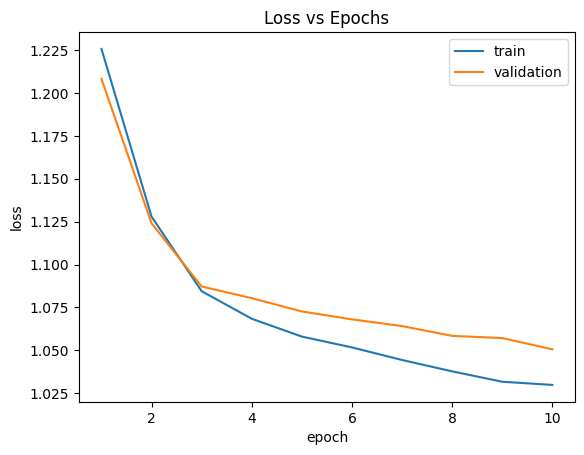

In [ ]:
plot_history(history, "loss", "Loss vs Epochs")

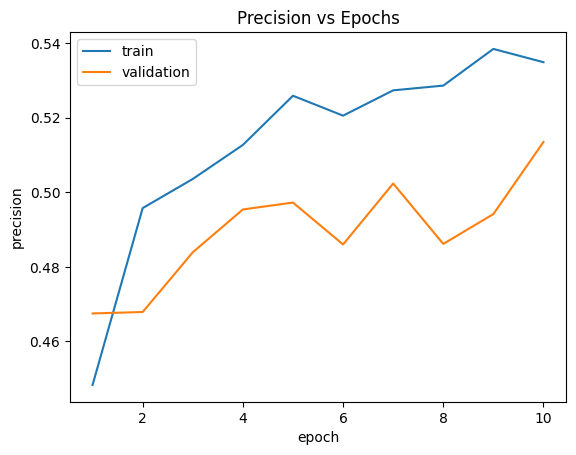

In [ ]:
plot_history(history, "precision", "Precision vs Epochs")

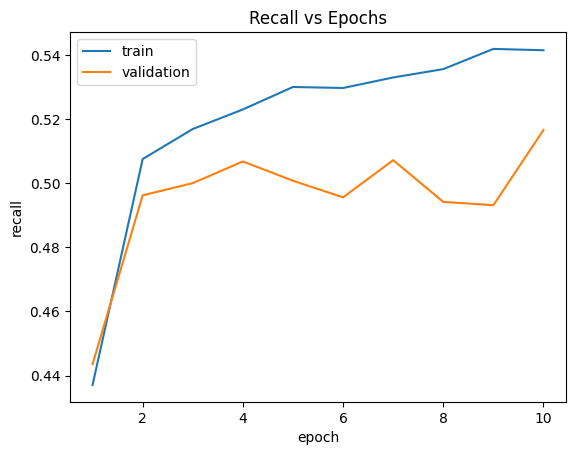

In [ ]:
plot_history(history, "recall", "Recall vs Epochs")

### What Does the Baseline Tell Us?

Looking at the three curves, after 10 epochs the training and validation losses are still high and still coming down, and precision and recall are far from where we would want them. The model has not finished learning.

# Orthogonalization

We have a baseline that is not good enough, and a long list of things we could try: more epochs, a deeper network, regularization, a different optimizer, more data. If we try them at random, we can spend months experimenting and never know what helped. So the question is: how do we know which knob to turn for which problem?

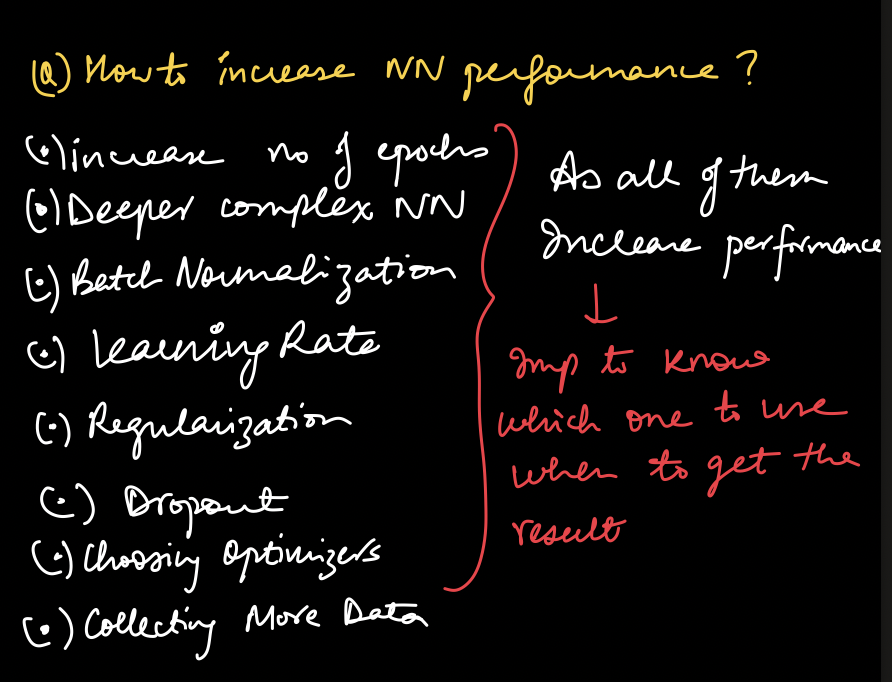

### What Can Be Done to Make the Model Perform Better?

**Ask Learners:** Looking at our baseline, what can we do to make it perform better? Drop your ideas in the chat.

There are many things that can be done to the baseline model, such as:
- Training for more epochs
- Trying a deeper neural network
- Adding L2 regularization
- Using batch normalization
- Trying dropout
- Simply changing the neural network architecture
- Collecting more data

All of them can improve performance, but each one fixes a different problem. It is really important to know what to try for which problem. Otherwise, we spend months experimenting and never get the result we want.

The process of knowing which knob to tune in order to achieve one specific effect is called **Orthogonalization**.

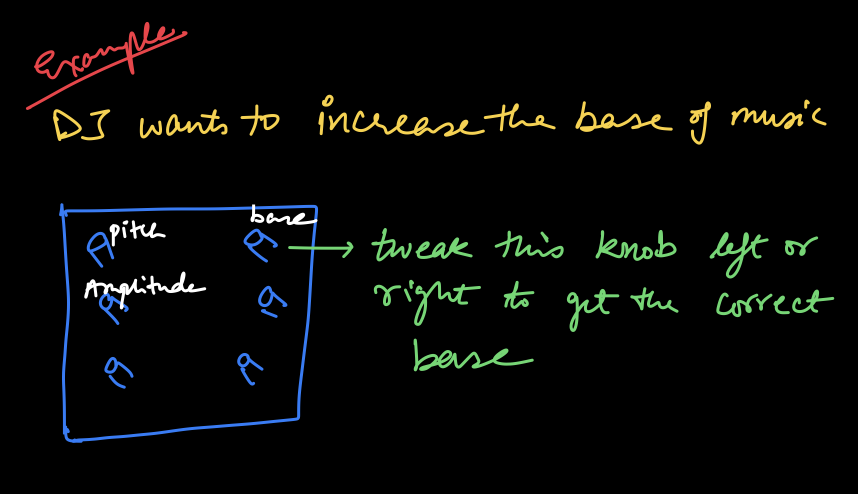

### Orthogonalization: The DJ Mixer Analogy

Imagine a DJ mixer and all its knobs.
- One knob controls the pitch of the audio.
- One knob controls the amplitude of the audio.
- One knob increases the bass of the audio.

If the DJ wants more bass, there is exactly one knob to turn. If one knob changed pitch, amplitude and bass together, nobody could control the sound.

Similarly, every idea for improving the model is a knob. It is important to know which knob to tune, and by how much, to get the model to perform better.

In a real team, this is also the rule for experiments: change one thing at a time. If three things change in one run and the metric moves, nobody can say which change caused it.

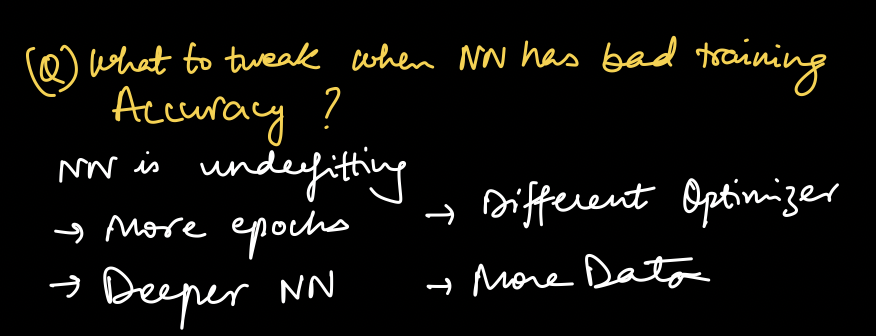

### What to Tweak When the Model Does Not Fit the Training Set

If the model does not fit the training set well, it is **underfitting**. The knobs for this problem are:
- A bigger network (more layers or more neurons)
- A different optimizer, preferably Adam
- Training for more epochs

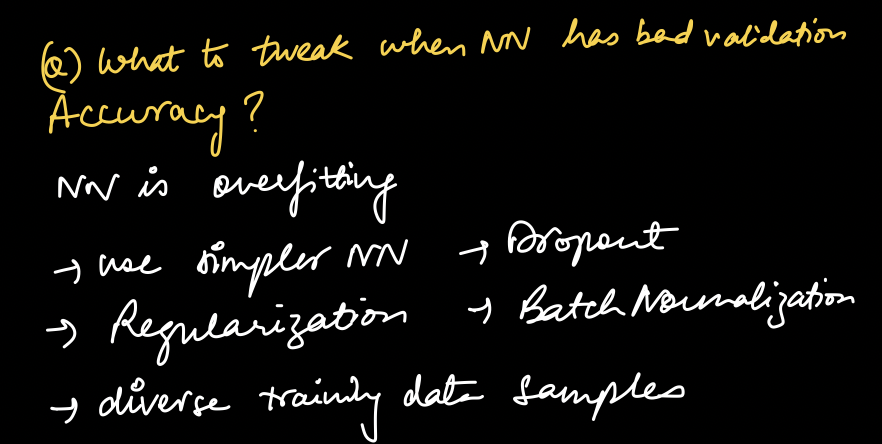

### What to Tweak When the Model Fits the Training Set but Performs Poorly on the Validation Set

This is clearly the case of **overfitting**. The knobs for this problem are:
- Regularization (L2, dropout, batch normalization)
- A simpler network
- More training data with diverse samples

**Doubt by Learner:** What is a diverse sample in the training data?

The new samples should look different from what the model has already seen, for example customers from other cities or age groups. More samples of the same kind add little new information.

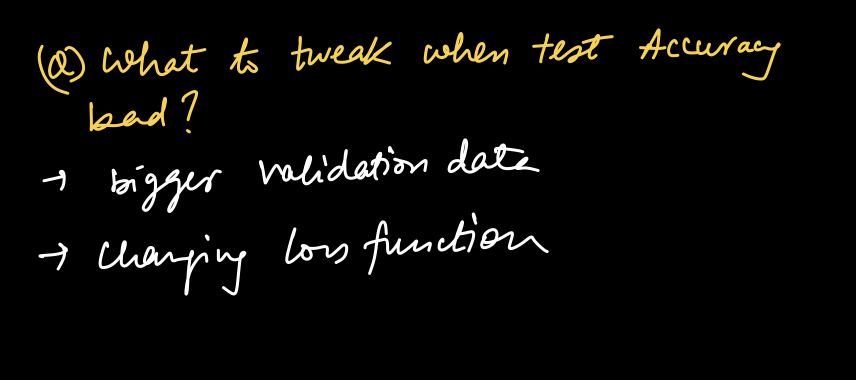

### What To Tweak When the Test Performance Is Poor but Training and Validation Performance Are Good

The chances of this happening are low, but if it does happen, the most common cause is that the validation set is too small or does not represent the real data. The model, or the hyperparameters we tuned, may have overfit the validation set. The fix is to get a bigger and more representative validation set.

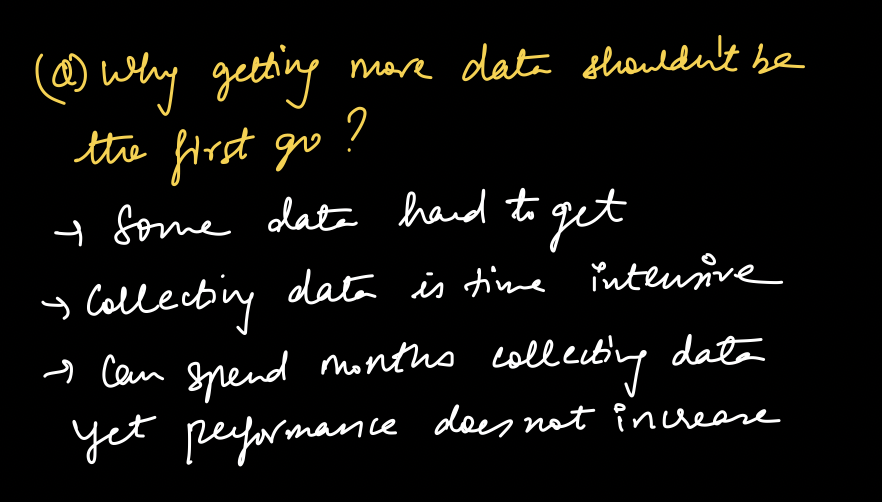

### Why Collecting More Data Should Not Be the First Move

Collecting more data looks like the safest answer, but it should not be the first one:
- Some data is hard to get.
- Collecting data is time-intensive.
- We can spend months collecting data and still see no improvement in performance.

So we diagnose first. Cheap knobs come before expensive ones.

### Putting It Together: From Symptom to Knob

| What we observe | Diagnosis | Knobs to try |
|:--|:--|:--|
| High training error | Underfitting (high bias) | Bigger network, different optimizer, more epochs |
| Low training error, high validation error | Overfitting (high variance) | Regularization, dropout, simpler network, more diverse data |
| Good training and validation error, poor test error | Validation set too small or not representative | Bigger and more representative validation set |

### Diagnose Our Baseline, Then Let AI Challenge You

**Ask Learners:** Look at the loss curves of our baseline once more. Is it underfitting or overfitting? Vote with an emoji: 🔼 for underfitting, 🔽 for overfitting.

The training and validation losses are close to each other, and both are high and still falling. There is no widening gap between them, so this is not overfitting. The model is underfitting: it has not yet learned the training data well.

Now let's check this diagnosis against an AI assistant.

**Step 1:** Write your own diagnosis and the single knob you would turn first, in one sentence, in the chat.

**Step 2:** Open the AI assistant in Colab, or any LLM assistant you like. Give it only these facts: the architecture, the optimizer, the number of epochs, the batch size, and the final training and validation loss. Ask: "What is the most likely diagnosis? Rank the next three changes and say which symptom each one fixes."

**Step 3:** Check the answer against the symptom-to-knob table. Does every suggested change match the symptom? Did the AI suggest changing several knobs together?

**Step 4:** Post in the chat one suggestion that you accept and one that you reject, with your reason.

### Quiz: Diagnosing the Problem

**Question:** A model reaches 99% accuracy on the training set but only 84% on the validation set. Which single change targets this problem best?

- A. Train for many more epochs using the same settings
- B. Switch to a different optimizer such as RMSprop
- C. Add dropout between the hidden layers of the model
- D. Make the network deeper with several extra hidden layers

The gap between 99% on training and 84% on validation is a variance problem: the model memorizes the training set. Dropout is a regularizer, so it targets exactly this symptom. More epochs and a deeper network add fitting power, which widens the gap further. A different optimizer mainly changes how fast the training error falls, not how well the model generalizes.

### Interview Checkpoint: Orthogonalization

**Ask Learners:** An interviewer asks: "What is orthogonalization in the context of training neural networks, and why does it matter?" Type a one-line answer in the chat.

## Which Hyperparameters to Tune, and in What Order

Many of the knobs we just listed are settings of the training process: the learning rate, the batch size, the number of neurons and so on. These are called hyperparameters, and we cannot tune all of them at once. So which ones matter most?

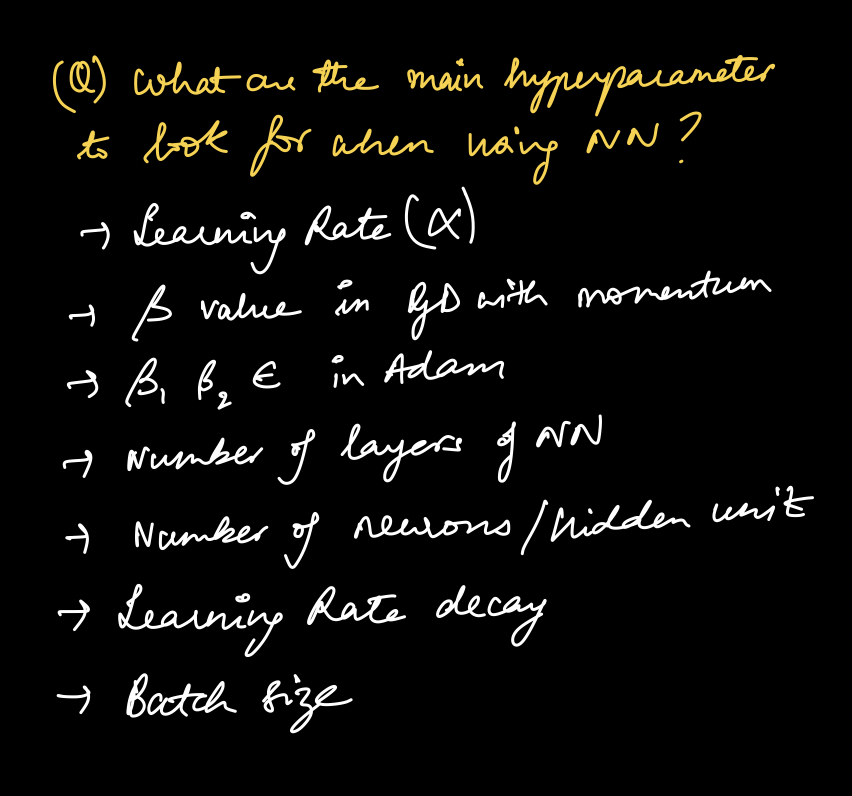

### What Are the Main Hyperparameters of a Neural Network?

The main hyperparameters are:
- Learning rate $\alpha$
- $\beta$ if using Gradient Descent with Momentum
- $\beta_1, \beta_2, \epsilon$ when using Adam
- Number of layers of the neural network
- Number of neurons / hidden units
- Learning rate decay
- Batch size

**Ask Learners:** If you could tune only one of these, which would it be? Type it in the chat.

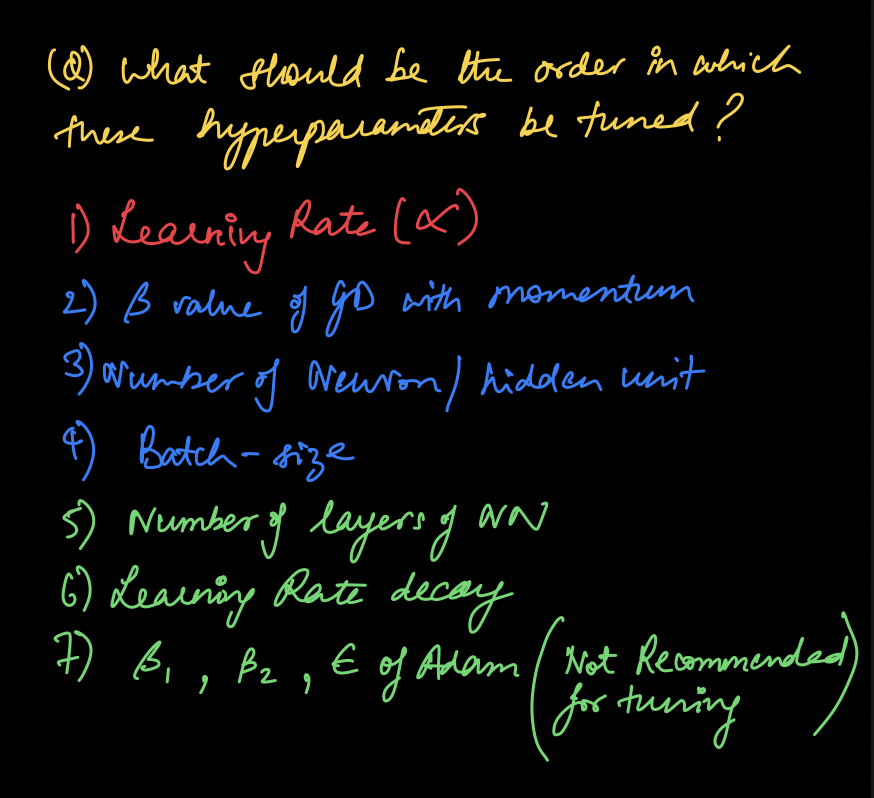

### In What Order Should the Hyperparameters Be Tuned?

The first one to tune is the **learning rate $\alpha$**. Most of the time, an incorrect $\alpha$ is the reason the model fails to train properly.

After the learning rate, the order is:
- **$\beta$ value**: a value of 0.9 is a good default.
- **Number of neurons / hidden units**: they decide how complex the model can become.
- **Batch size**: it controls how noisy each update is and how much memory each step needs.

The hyperparameters to tune last are:
- **Number of layers**: adding layers changes the network entirely, so it is a final resort.
- **Learning rate decay**: if the model still does not perform after finding the best learning rate, decay the learning rate over the epochs.
- **$\beta_1, \beta_2, \epsilon$ of Adam**: tuning these is not recommended, but sometimes it helps the model converge.

### Learning Rate: Testing the Claim Instead of Believing It

We said that the learning rate is the first hyperparameter to tune. Let's test that claim. We train the same baseline network five times with the same data, the same starting weights and the same optimizer. Only the learning rate changes: 0.00001, 0.001, 0.01, 0.1 and 1.0.

**Ask Learners:** Predict which learning rate will give the lowest validation loss after 10 epochs. Type your pick in the chat.

Here's the code: we loop over five learning rates, resetting the random seed before each one so every run starts from identical weights, and store each run's full history.

In [ ]:
lr_results = {}
for lr in [1e-5, 1e-3, 1e-2, 1e-1, 1.0]:
    torch.manual_seed(42)                                   # same starting weights for every run
    lr_results[lr] = train_model(create_baseline(X_train_t.shape[1]), lr=lr, epochs=10)

### Plot and Compare

We plot every run's validation loss on a shared log-scale y-axis (so a diverging run doesn't squash the others flat), then tabulate each run's final validation loss for a quick side-by-side read.

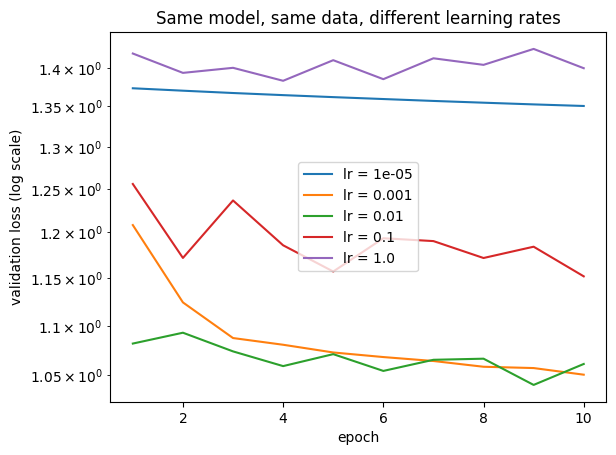

,final validation loss
0.00001,1.3506
0.00100,1.0506
0.01000,1.0612
0.10000,1.1518
1.00000,1.3991


In [ ]:
for lr, h in lr_results.items():
    plt.plot(range(1, 11), h["val_loss"], label=f"lr = {lr}")
plt.xlabel("epoch")
plt.ylabel("validation loss (log scale)")
plt.yscale("log")                                           # a log scale keeps a diverging run from hiding the others
plt.legend()
plt.title("Same model, same data, different learning rates")
plt.show()

pd.Series({lr: round(h["val_loss"][-1], 4) for lr, h in lr_results.items()}, name="final validation loss")

The learning rates at the two extremes do badly. A very small learning rate barely moves the loss in 10 epochs. A very large learning rate makes the loss jump around or get stuck. Only the values in the middle train properly. Same data, same network, same optimizer, and one number decided whether the model learns at all.

In industry, a wrong learning rate looks exactly like a model that cannot learn the problem. Teams lose weeks by concluding that the architecture is bad when the learning rate was the culprit.

**Doubt by Learner (Optional):** Why do we search the learning rate on a log scale?

The useful values span several orders of magnitude, from $10^{-5}$ to $10^{-1}$. If we sample uniformly between 0.00001 and 0.1, about 90% of the samples land above 0.01 and small values are almost never tested. Sampling the exponent uniformly gives every order of magnitude the same attention.

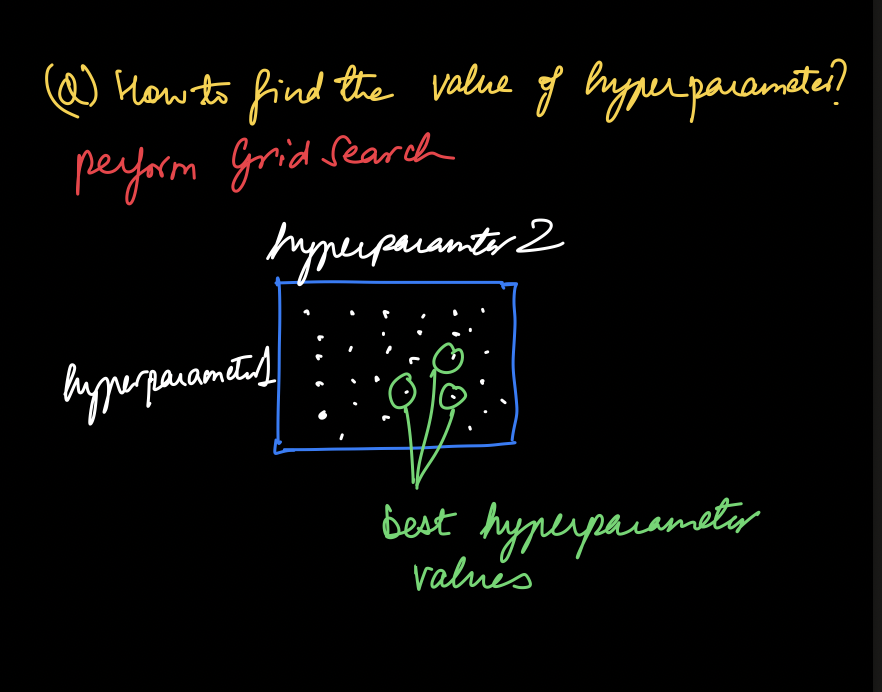

### How to Find the Value of a Hyperparameter?

By performing a **Grid Search**: we pick a few values for each hyperparameter and train a model for every combination.

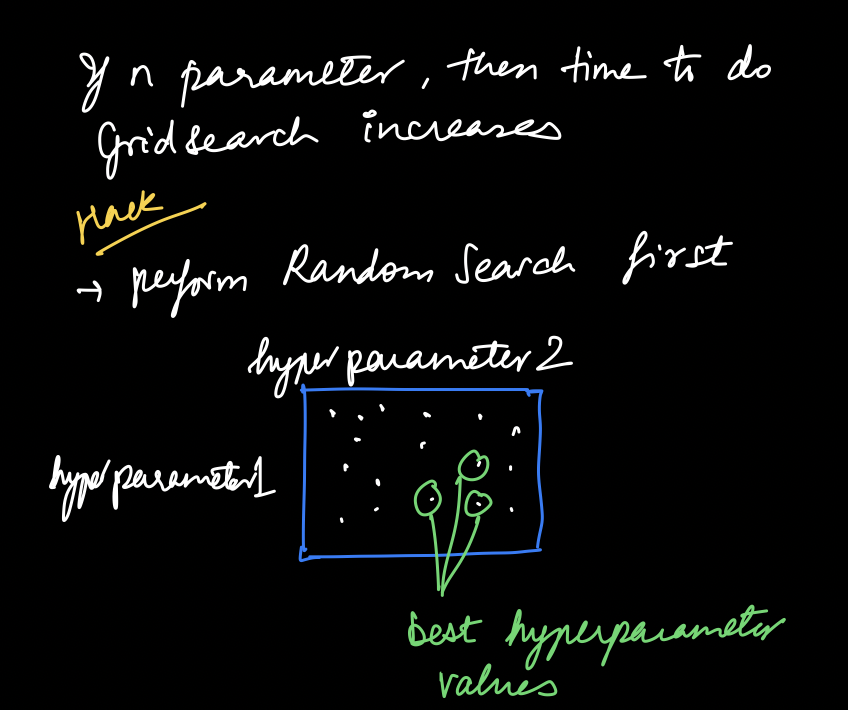

### What if There Are N Hyperparameters? Will Grid Search Still Work?

No. As the number of hyperparameters increases, the number of combinations, and with it the time of grid search, grows very fast. Every grid point is one full training run, which means more hours of compute and more money.

There is a hack to avoid this: try **Random Search** first to find the promising region.

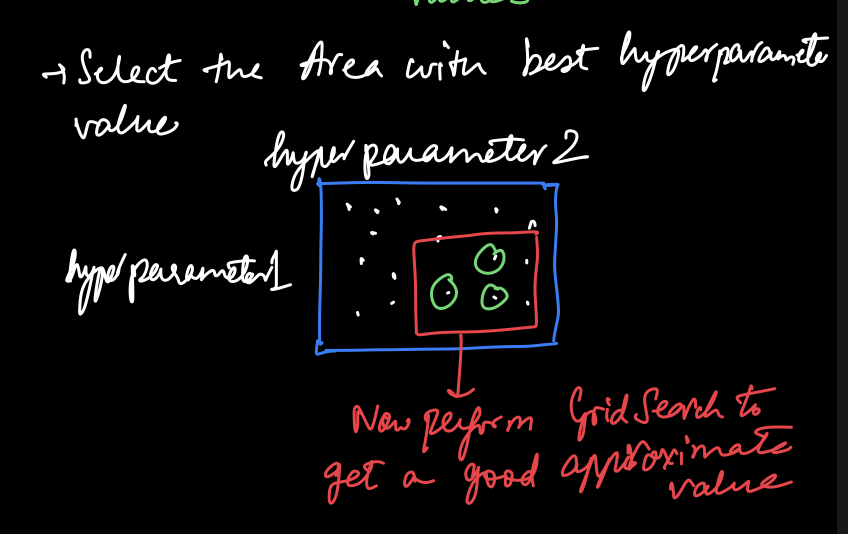

After the random search:
- Select the region of the best hyperparameter values.
- Perform a grid search inside that region.
- This gives a good approximate value of the hyperparameters to use.

### AI-Assisted Random Search Plan

Let's use an AI assistant to design the search space, and then let the data judge it.

**Step 1:** In the chat, write the hyperparameters you would search for our baseline and the range you would pick for each.

**Step 2:** Ask the AI assistant: "I am tuning a 4-hidden-layer MLP with Adam on a 4-class tabular problem. Propose a random search space for the learning rate and the batch size. Tell me which one should be sampled on a log scale and why."

**Step 3:** Compare the answer with your own list. Did it put the learning rate on a log scale? Does the range include values that we just saw fail?

**Step 4:** Run five random trials from the search space and look at the results.

### The Code

`10 ** rng.uniform(-4, -1)` is the log-uniform sampling trick from the Doubt above, applied directly: it draws a random exponent between −4 and −1 and raises 10 to that power, so every order of magnitude between 1e-4 and 1e-1 is equally likely to be picked. `rng.choice([...])` picks a batch size uniformly from a short list of common values. Each of the 5 trials gets a fresh random `lr`/`bs` pair, trains a fresh model, and we keep its final validation loss and F1.

In [ ]:
rng = np.random.default_rng(0)
trials = []
for t in range(5):
    lr = 10 ** rng.uniform(-4, -1)                         # log-uniform sample between 1e-4 and 1e-1
    bs = int(rng.choice([32, 64, 128, 256]))
    torch.manual_seed(42)
    h = train_model(create_baseline(X_train_t.shape[1]), lr=lr, epochs=10, batch_size=bs)
    trials.append((round(lr, 5), bs, round(h["val_loss"][-1], 4), round(h["val_f1"][-1], 4)))

### Results, Sorted by Validation Loss

Wrapping the trials in a `DataFrame` and sorting by `val_loss` makes the best-performing combinations easy to spot at a glance.

In [ ]:
pd.DataFrame(trials, columns=["lr", "batch_size", "val_loss", "val_f1"]).sort_values("val_loss")

,lr,batch_size,val_loss,val_f1
0,0.00814,128,1.0486,0.5136
4,0.00661,256,1.0589,0.5094
3,0.05474,256,1.0695,0.5116
2,0.00011,32,1.0900,0.4849
1,0.00013,64,1.1114,0.4700


The best rows show the region worth exploring further. The next step would be a finer grid search inside that region.

### Quiz: Random Search versus Grid Search

**Question:** You can afford 25 training runs to tune two hyperparameters: the learning rate, which matters a lot, and the batch size, which matters little. Why is random search usually better than a 5 × 5 grid here?

- A. It tests 25 different learning rates, while the grid tests 5
- B. It guarantees that the best values are found within just 25 runs
- C. It needs fewer training runs than a grid to cover the same space
- D. It removes the need for a separate validation set when tuning

In a 5 × 5 grid, every learning rate is repeated 5 times with different batch sizes, so only 5 distinct learning rates are ever tried. Random search picks a new value for every hyperparameter in every run, so 25 runs test 25 distinct learning rates. When one hyperparameter matters far more than the others, this gives a much better chance of landing near its best value. Random search gives no guarantee, uses the same number of runs, and still needs a validation set.

## End of Part 1 — What's Next in Part 2

Today we built a baseline model, learned to diagnose *why* it underperforms with orthogonalization, and worked out which hyperparameter to tune first and how to search for it efficiently.

In Part 2, we'll pick up right where we left off (the same baseline model, retrained from the same seeds) and cover:

- **Gradient Checking** — proving backpropagation itself is bug-free
- **Single Evaluation Metric** — picking a metric that can't quietly hide a bad model
- **Human-level Performance** — knowing when a model is actually good enough to ship
- **Multi-task Learning** — handling inputs that carry more than one correct label